In [1]:
!pip install 'qiskit[visualization]' qiskit-ibm-runtime qiskit-aer
# Core Qiskit imports
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# IBM Runtime specific imports
from qiskit_ibm_runtime import SamplerV2 as Sampler, QiskitRuntimeService

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 2.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 54.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 386.9/386.9 kB 25.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.3/111.3 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.6/71.6 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 66.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 66.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 218.0/218.0 kB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.6/54.6 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.4/76.4 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.2/130.2 kB 9.9 MB/s eta 0:00:00
  Created wh

In [2]:
import sys

import qiskit
import qiskit_aer
import qiskit_ibm_runtime

print("Python:", sys.version.split()[0])
print("qiskit:", qiskit.__version__)
print("qiskit-aer:", qiskit_aer.__version__)
print("qiskit-ibm-runtime:", qiskit_ibm_runtime.__version__)

Python: 3.12.13
qiskit: 2.4.2
qiskit-aer: 0.17.2
qiskit-ibm-runtime: 0.47.0


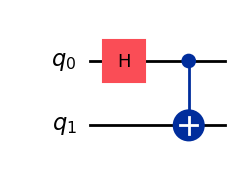

Counts:
{'00': 484, '11': 516}

Energy:
0.9999999999999998


In [23]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp

# =====================================
# 1) Build Bell State
# =====================================

qc = QuantumCircuit(2)

qc.h(0)
qc.cx(0, 1)
display(qc.draw("mpl"))# =====================================
# 2) Sampler Part (Measurement Counts)
# =====================================

qc_measure = qc.copy()
qc_measure.measure_all()

from qiskit_aer import AerSimulator

sim = AerSimulator()

job = sim.run(
    qc_measure,
    shots=1000
)

result = job.result()

counts = result.get_counts()

print("Counts:")
print(counts)

# =====================================
# 3) Hamiltonian
# =====================================

J = 1
hx = 5

obs = SparsePauliOp.from_list([
    ("ZZ", J),
    ("XI", hx),
    ("IX", hx)
])

# =====================================
# 4) Transpile
# =====================================

from qiskit.transpiler.preset_passmanagers import (
    generate_preset_pass_manager
)

backend = AerSimulator()

pm = generate_preset_pass_manager(
    backend=backend,
    optimization_level=3
)

qc_isa = pm.run(qc)

obs_isa = obs.apply_layout(
    layout=qc_isa.layout
)

# =====================================
# 5) Estimator Part (Energy)
# =====================================

from qiskit.primitives import StatevectorEstimator

estimator = StatevectorEstimator()

job = estimator.run([
    (qc_isa, obs_isa)
])

result = job.result()

energy = result[0].data.evs

print("\nEnergy:")
print(energy)